# 04 · Compare clean dummy and logistic baselines

Does learning recorded age, sex and site improve on assigning everyone the training prevalence? Reproduce the original baseline comparison on retained images, with transparent exploratory cutoff illustrations.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [04_dummy_logistic_baseline.ipynb](../Subset/04_dummy_logistic_baseline.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '04_metadata_baselines'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Load matching saved predictions and explain the protocol

The dummy learns only training prevalence. Categorical-age logistic regression uses one-hot age, sex and site, C=1 and liblinear. Every prediction comes from a fit excluding that patient's entire outer fold. ID, diagnosis, target and fold are never predictors; category levels are learned within fitting patients. These cells load the approved fits rather than train again.

In [2]:
import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))

names = ["dummy", "categorical_logistic"]
metrics = metric_table(frame, scores, names)
display(pd.DataFrame([{"model": LABELS[name], "inputs": "sex, age category, site" if name != "dummy" else "training prevalence only", "outer fits": 5} for name in names]))

,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


,model,inputs,outer fits
0,Training-prevalence dummy,training prevalence only,5
1,Categorical-age logistic,"sex, age category, site",5


## 2. Check the prior baseline against preserved folds

The dummy must give one constant score within each outer fold. Its held-out fold AUC is 0.5 and its AP equals that fold's malignant prevalence. The training prevalence need not match validation prevalence, so pooled dummy AUC need not be exactly 0.5.

In [3]:
check = frame.assign(dummy_score=scores["dummy"]).groupby("fold").agg(images=("target", "size"), malignant_images=("target", "sum"), validation_prevalence=("target", "mean"), training_prior=("dummy_score", "first"), distinct_scores=("dummy_score", "nunique"))
dummy_fold = metrics.loc[metrics.model.eq("dummy") & metrics.scope.eq("fold")].set_index("fold")
check["heldout_AP"] = dummy_fold.average_precision
check["heldout_AUC"] = dummy_fold.roc_auc
assert check.distinct_scores.eq(1).all()
assert np.allclose(check.heldout_AUC, .5)
assert np.allclose(check.heldout_AP, check.validation_prevalence)
display(check.round(5))

,images,malignant_images,validation_prevalence,training_prior,distinct_scores,heldout_AP,heldout_AUC
fold,,,,,,,
0,1344,24,0.01786,0.01921,1,0.01786,0.5
1,1366,26,0.01903,0.01891,1,0.01903,0.5
2,1328,26,0.01958,0.01878,1,0.01958,0.5
3,1371,25,0.01823,0.01912,1,0.01823,0.5
4,1297,26,0.02005,0.01867,1,0.02005,0.5


## 3. Compare primary and secondary probability metrics

Read mean-fold AP first: it gives each preserved patient fold equal weight. Larger AP/AUC means better ranking; smaller log loss/Brier means smaller probability error. Pooled results are secondary and weight larger folds more heavily. Low Brier alone can disguise poor detection when malignancy is rare.

,model,scope,fold,average_precision,roc_auc,log_loss,brier
5,dummy,mean_fold,NaN,0.01895,0.50000,0.09393,0.01859
6,dummy,pooled,NaN,0.01839,0.48774,0.09389,0.01858
12,categorical_logistic,mean_fold,NaN,0.05669,0.59695,0.09244,0.01849
13,categorical_logistic,pooled,NaN,0.04296,0.59429,0.09237,0.01848


average_precision                      roc_auc      
model categorical_logistic   dummy categorical_logistic dummy
fold                                                         
0.0                 0.0442  0.0179               0.6443   0.5
1.0                 0.0488  0.0190               0.5042   0.5
2.0                 0.0327  0.0196               0.5513   0.5
3.0                 0.0663  0.0182               0.7051   0.5
4.0                 0.0915  0.0200               0.5798   0.5

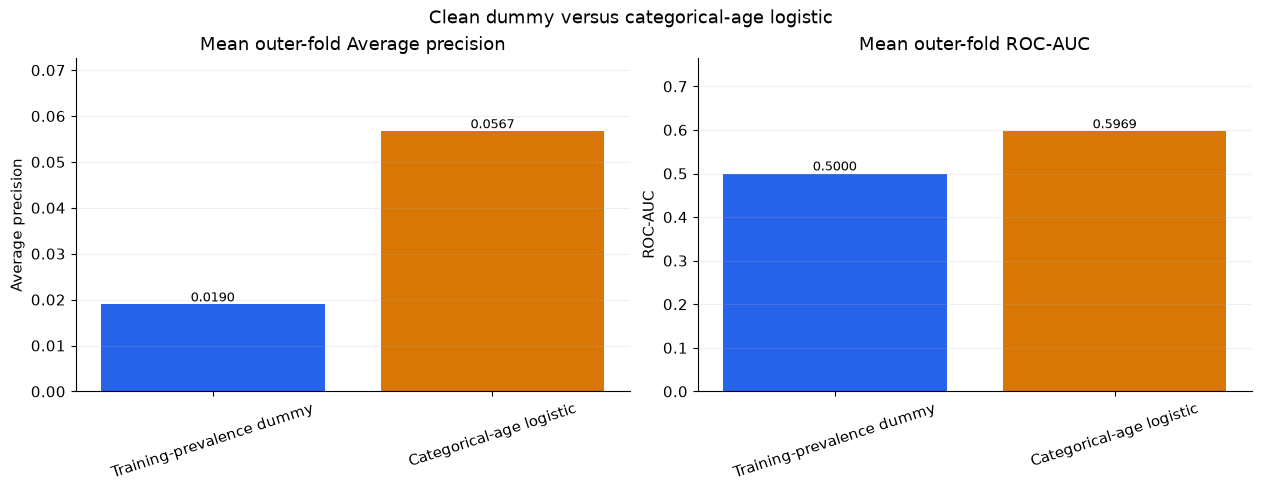

In [4]:
display(metrics.loc[metrics.scope.ne("fold")].round(5))
display(metrics.loc[metrics.scope.eq("fold")].pivot(index="fold", columns="model", values=["average_precision", "roc_auc"]).round(4))
finish_figure(metric_bar_figure(metrics, names, "Clean dummy versus categorical-age logistic"), "baseline_ranking")

## 4. Read the held-out ROC and precision–recall curves

ROC plots false-positive fraction against recall; nearer the upper left is preferable. PR plots recall against the malignant fraction among flagged images; compare precision at a common recall. The horizontal baseline is observed prevalence. The recall-zero endpoint does not establish perfect detection.

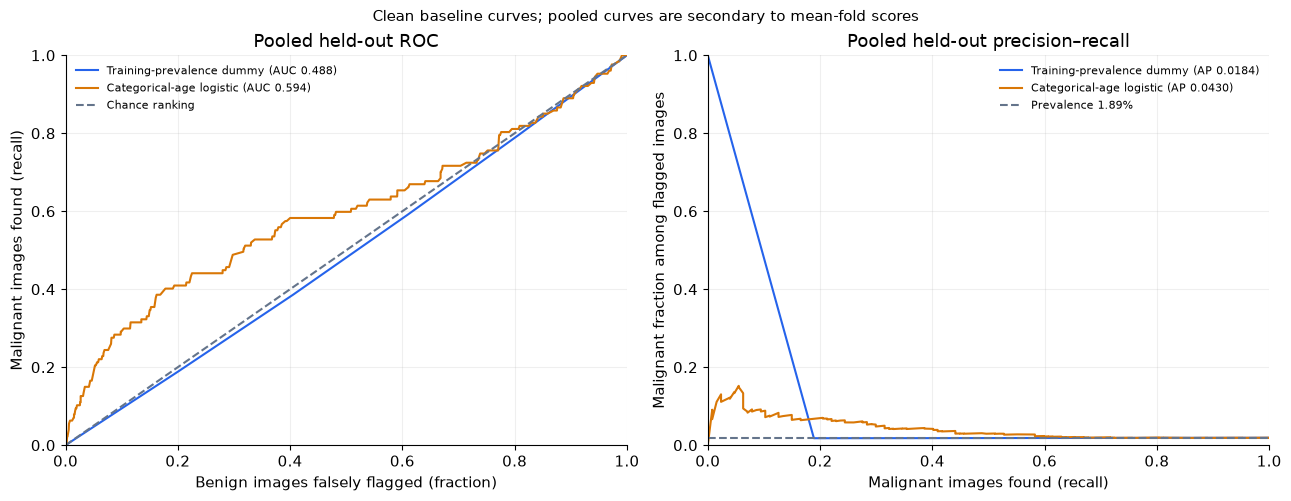

In [5]:
finish_figure(curve_figure(frame, scores, names, "Clean baseline curves"), "baseline_roc_pr")

## 5. Inspect decisions at the fixed 0.50 cutoff

A fixed cutoff is a descriptive scenario, not a clinical rule. Each matrix prints TN/FP/FN/TP and percentages within benign or malignant rows. Compare missed malignant cases with false alarms and flagged fraction; an excellent overall error rate can coexist with poor malignant recall.

,model,cutoff,role,balanced_accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,dummy,0.5,Fixed descriptive cutoff,0.5,0,0,6579,127,0.0,1.0,NaN,0.0
1,categorical_logistic,0.5,Fixed descriptive cutoff,0.5,0,0,6579,127,0.0,1.0,NaN,0.0


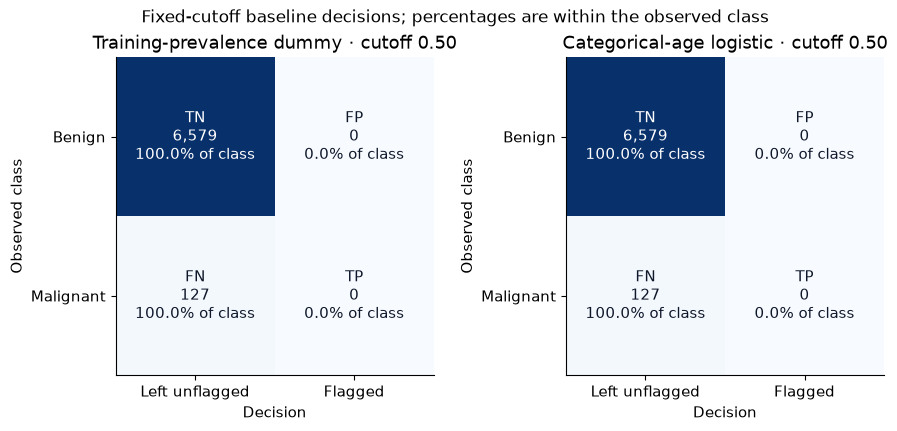

In [6]:
fixed = cutoff_table(frame, scores, names)
display(fixed.round(5))
scenarios = [(LABELS[name] + " · cutoff 0.50", np.asarray(scores[name]) >= .5) for name in names]
finish_figure(confusion_figure(frame.target, scenarios, "Fixed-cutoff baseline decisions"), "baseline_confusions_05")

## 6. Reproduce the original exploratory cutoff illustration

This secondary illustration chooses the logistic cutoff maximising OOF balanced accuracy, then uses those same OOF labels to report it. That overlap can overstate future performance. It is excluded from the primary model-choice claims and never exported as the final cutoff. The dummy remains at 0.50; notebook 08 uses training-only cutoff rules instead.

,model,cutoff,role,balanced_accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,dummy,0.50000,Fixed descriptive cutoff,0.50000,0,0,6579,127,0.00000,1.00000,NaN,0.00000
1,categorical_logistic,0.02719,OOF-selected illustration; selection and asses...,0.61187,51,1170,5409,76,0.40157,0.82216,0.04177,0.18208


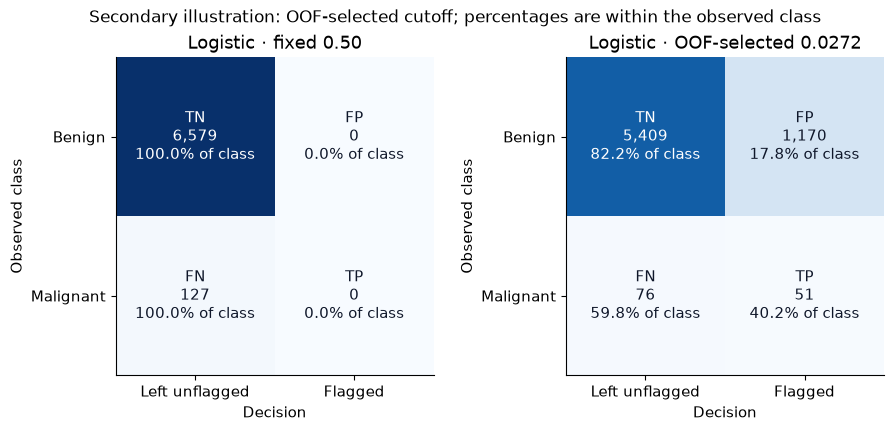

In [7]:
exploratory = cutoff_table(frame, scores, names, exploratory=True)
display(exploratory.round(5))
cutoff = exploratory.set_index("model").loc["categorical_logistic", "cutoff"]
scenarios = [("Logistic · fixed 0.50", scores["categorical_logistic"] >= .5), (f"Logistic · OOF-selected {cutoff:.4f}", scores["categorical_logistic"] >= cutoff)]
finish_figure(confusion_figure(frame.target, scenarios, "Secondary illustration: OOF-selected cutoff"), "baseline_exploratory_confusions")

## 7. Inspect saved logistic associations and state the limits

Coefficients describe regularised associations among encoded categories; they are neither causes nor stable patient risk factors. A category absent from one training fold has no coefficient in that fit. Error bars below show variability across available saved fits, not sampling confidence intervals. This remains a development comparison before image information.

,mean,std,count
encoded_feature,,,
categorical__sex_female,-1.1640,0.0555,5
categorical__age_approx_35,-0.9953,0.2193,5
categorical__sex_male,-0.9412,0.1134,5
categorical__age_approx_40,-0.8113,0.2946,5
categorical__anatom_site_general_challenge_palms/soles,-0.8039,0.0365,5
categorical__age_approx_25,-0.7276,0.1442,5
categorical__anatom_site_general_challenge_lower extremity,-0.7093,0.1185,5
categorical__anatom_site_general_challenge_torso,-0.6823,0.0855,5
categorical__age_approx_45,-0.6294,0.1410,5


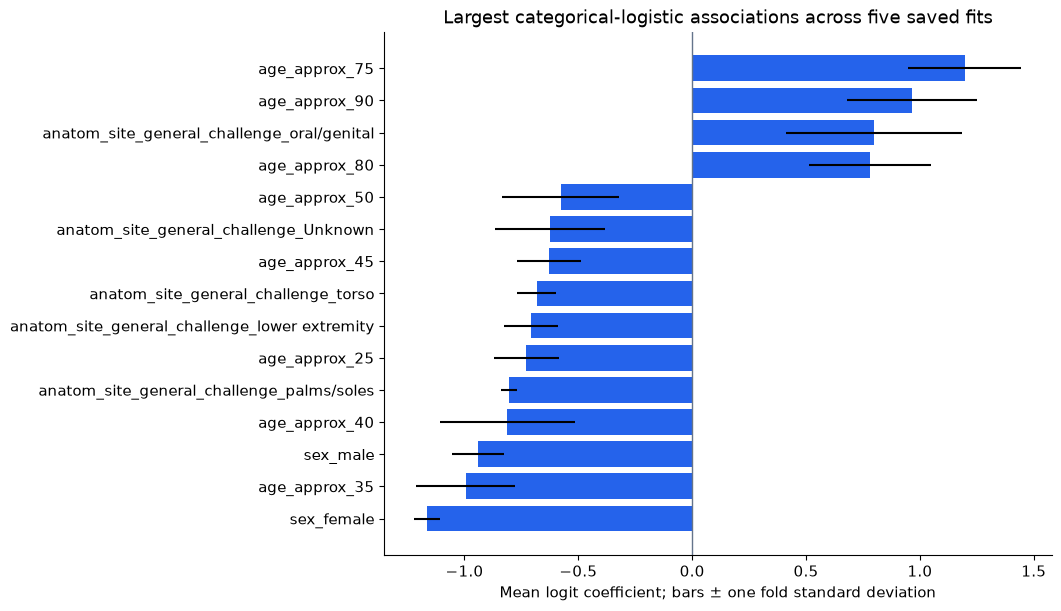

Mean-fold AP: dummy **0.0190**, logistic **0.0567**. The fixed-cutoff and OOF-selected matrices describe different decision scenarios; only the latter reuses scoring labels to choose a cutoff. No reserved-test conclusion follows.

In [8]:
coefficients, _, _ = estimator_diagnostics(meta)
summary = coefficients.groupby("encoded_feature").logit_coefficient.agg(["mean", "std", "count"])
selected = summary.reindex(summary["mean"].abs().nlargest(15).index).sort_values("mean")
display(selected.round(4))
fig, ax = plt.subplots(figsize=(10.5, 6), layout="constrained")
ax.barh(selected.index.str.replace("categorical__", "", regex=False), selected["mean"], xerr=selected["std"].fillna(0), color="#2563eb")
ax.axvline(0, color="#64748b", linewidth=1)
ax.set(title="Largest categorical-logistic associations across five saved fits", xlabel="Mean logit coefficient; bars ± one fold standard deviation")
finish_figure(fig, "baseline_logistic_coefficients")
gain = metrics.loc[metrics.scope.eq("mean_fold")].set_index("model").average_precision
display(Markdown(f"Mean-fold AP: dummy **{gain['dummy']:.4f}**, logistic **{gain['categorical_logistic']:.4f}**. The fixed-cutoff and OOF-selected matrices describe different decision scenarios; only the latter reuses scoring labels to choose a cutoff. No reserved-test conclusion follows."))

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.